In [ ]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


In [ ]:
train = pd.read_csv("/content/08758214-ae0c-4fb9-bd84-85d256f7b48f-train (1).csv")
train.head()

,request_id,created_at_ist,channel,product_family,warranty_status,request_text,source,team_label
0,SR500000,2025-04-01 00:31,whatsapp,Robot Vacuum,shield,sir how to clean robot vacuum reg no SR75294,legacy_zoho,Product Advice
1,SR500001,2025-04-01 01:27,chat,Water Purifier,out_of_warranty,"hello team, emi conversion not done for purifi...",legacy_zoho,Billing
2,SR500002,2025-04-01 03:26,whatsapp,Water Purifier,in_warranty,claim status for purifier under warranty paid ...,legacy_zoho,Billing
3,SR500003,2025-04-01 04:50,chat,Robot Vacuum,in_warranty,sir spare blade set for fan available? asap,legacy_zoho,Consumables
4,SR500004,2025-04-01 06:39,ivr,Air Fryer,out_of_warranty,"hi, display of air fryer gone blank thanks",legacy_zoho,Repairs


In [ ]:
train.columns

Index(['request_id', 'created_at_ist', 'channel', 'product_family',
       'warranty_status', 'request_text', 'source', 'team_label'],
      dtype='object')

In [ ]:
resolution_log_df = pd.read_csv("/content/3b74ba57-8e89-48c7-becc-f229c8ddbdb4-resolution_log.csv")
resolution_log_df.head()

,request_id,first_team,final_team,transfers,resolved_at
0,SR500000,Product Advice,Product Advice,0,2025-04-01 11:04
1,SR500001,Billing,Billing,0,2025-03-31 22:41
2,SR500002,Billing,Warranty Claims,1,2025-04-01 13:26
3,SR500003,Consumables,Consumables,0,2025-04-01 11:07
4,SR500004,Repairs,Repairs,1,2025-04-01 09:18


In [ ]:
resolution_log_df.columns

Index(['request_id', 'first_team', 'final_team', 'transfers', 'resolved_at'], dtype='object')

In [ ]:
test = pd.read_csv("/content/a85b92d4-2e95-4877-9628-629f67ec3dcf-test_unlabelled.csv")
sample = pd.read_csv("/content/a9235996-dae0-4069-bfe2-dd3f6cd2f08d-sample_submission.csv")

In [ ]:
print("Train:", train.shape)
print("Test:", test.shape)
print("Submission template:", sample.shape)
print(train["team_label"].value_counts(dropna=False))
print("Duplicate training IDs:", train["request_id"].duplicated().sum())

Train: (10822, 8)
Test: (2178, 7)
Submission template: (2178, 2)
team_label
Repairs                  3129
Billing                  1656
Product Advice           1180
Returns & Replacement    1174
Warranty Claims          1040
Consumables               927
Installations             745
Filters & Consumables     531
Installs & Demo           440
Name: count, dtype: int64
Duplicate training IDs: 0


The training data contains 9 distinct labels, even though the task brief says there should be 7 team names. Maybe the potential issue is that Installs & Demo and Installations might be separate labels or historical naming variations. Similarly, Consumables and Filters & Consumables might represent different teams.

In [ ]:
teams_df = pd.read_csv("/content/697fb5c8-4f7c-4152-9504-1065b9b4fa60-teams.csv")

print(teams_df.columns.tolist())
print(teams_df.to_string(index=False))

print("\nDistinct training labels:")
print(sorted(train["team_label"].dropna().unique()))

['team', 'renamed_to', 'handles']
                 team                               renamed_to                                                                                                            handles
        Installations       Installs & Demo (from 15 Jan 2026)                                                           New-product installation, demo and wall-mounting visits.
              Repairs                                      NaN                   Product faults, breakdowns, error codes, noise, leaks - anything that needs a technician to fix.
          Consumables Filters & Consumables (from 15 Jan 2026)             Filters, candles, membranes, jars, brushes, blades, AMC kits - selling and fitting spares. Not faults.
              Billing                                      NaN Invoices, GST, double charges, refunds of payments, EMI conversion, coupons. Only when the problem IS the payment.
Returns & Replacement                                      NaN              

In [ ]:
print("TEST:", test.columns.tolist())
print("SAMPLE:", sample.columns.tolist())
print(sample.head())

TEST: ['request_id', 'created_at_ist', 'channel', 'product_family', 'warranty_status', 'request_text', 'source']
SAMPLE: ['request_id', 'team']
  request_id     team
0   SR510822  Repairs
1   SR510823  Repairs
2   SR510824  Repairs
3   SR510825  Repairs
4   SR510826  Repairs


In [ ]:

# Normalize team names (safe to run more than once)
team_mapping = {
    "Installations": "Installs & Demo",
    "Consumables": "Filters & Consumables"
}

train["team_label"] = train["team_label"].replace(team_mapping)

canonical_teams = {
    "Repairs",
    "Billing",
    "Product Advice",
    "Returns & Replacement",
    "Warranty Claims",
    "Filters & Consumables",
    "Installs & Demo"
}

observed_teams = set(train["team_label"].dropna().unique())

print("Number of canonical labels:", len(observed_teams))
print("Labels:", sorted(observed_teams))
print("Missing expected labels:", canonical_teams - observed_teams)
print("Unexpected labels:", observed_teams - canonical_teams)
print("Missing targets:", train["team_label"].isna().sum())
print("Duplicate training IDs:", train["request_id"].duplicated().sum())
print("Duplicate test IDs:", test["request_id"].duplicated().sum())

assert observed_teams == canonical_teams, "Investigate team labels before training"
assert train["team_label"].notna().all()


Number of canonical labels: 7
Labels: ['Billing', 'Filters & Consumables', 'Installs & Demo', 'Product Advice', 'Repairs', 'Returns & Replacement', 'Warranty Claims']
Missing expected labels: set()
Unexpected labels: set()
Missing targets: 0
Duplicate training IDs: 0
Duplicate test IDs: 0


In [ ]:
target = "team_label"
text_col = "request_text"

cat_cols = [
    "channel",
    "product_family",
    "warranty_status",
    "source"
]

num_cols = ["created_month", "created_dayofweek"]

for df in [train, test]:
    df["created_at_ist"] = pd.to_datetime(
        df["created_at_ist"], errors="coerce"
    )

    df["created_month"] = df["created_at_ist"].dt.month
    df["created_dayofweek"] = df["created_at_ist"].dt.dayofweek

    df[text_col] = df[text_col].fillna("").astype(str)

# Check missing values in the feature columns
print("Training feature missing values:")
print(train[[text_col] + cat_cols + num_cols].isna().sum())

print("\nTraining date range:")
print(train["created_at_ist"].min(), "to",
      train["created_at_ist"].max())

print("\nTest date range:")
print(test["created_at_ist"].min(), "to",
      test["created_at_ist"].max())


Training feature missing values:
request_text         0
channel              0
product_family       0
warranty_status      0
source               0
created_month        0
created_dayofweek    0
dtype: int64

Training date range:
2025-04-01 00:31:00 to 2026-06-30 23:33:00

Test date range:
2026-07-01 00:31:00 to 2026-09-30 23:00:00


In [ ]:
feature_cols = [text_col] + cat_cols + num_cols

X = train[feature_cols]
y = train[target]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_valid))
print("\nTraining label distribution:")
print(y_train.value_counts())
print("\nValidation label distribution:")
print(y_valid.value_counts())


Training examples: 8657
Validation examples: 2165

Training label distribution:
team_label
Repairs                  2503
Billing                  1325
Filters & Consumables    1166
Installs & Demo           948
Product Advice            944
Returns & Replacement     939
Warranty Claims           832
Name: count, dtype: int64

Validation label distribution:
team_label
Repairs                  626
Billing                  331
Filters & Consumables    292
Installs & Demo          237
Product Advice           236
Returns & Replacement    235
Warranty Claims          208
Name: count, dtype: int64


In [ ]:

# Preprocessing
preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=200_000,
        sublinear_tf=True
    ), text_col),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant", fill_value="missing"
        )),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols),

    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), num_cols)
])

Validation accuracy: 0.9492 (94.92%)
Validation Macro-F1: 0.9477

Classification report:
                       precision    recall  f1-score   support

              Billing       0.94      0.97      0.95       331
Filters & Consumables       0.92      0.93      0.93       292
      Installs & Demo       0.95      0.95      0.95       237
       Product Advice       0.95      0.95      0.95       236
              Repairs       0.98      0.94      0.96       626
Returns & Replacement       0.94      0.96      0.95       235
      Warranty Claims       0.95      0.95      0.95       208

             accuracy                           0.95      2165
            macro avg       0.94      0.95      0.95      2165
         weighted avg       0.95      0.95      0.95      2165



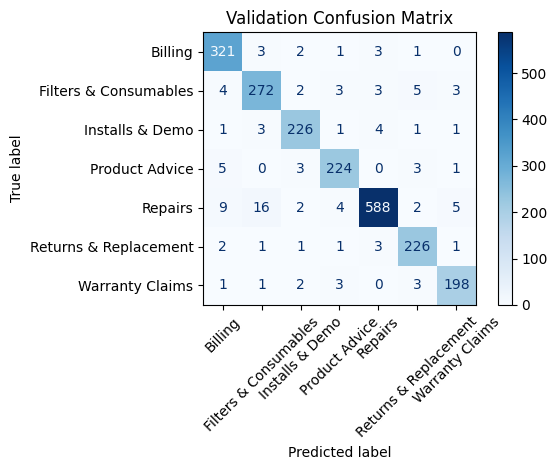

In [ ]:
# Full pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train
model.fit(X_train, y_train)

# Validate
valid_pred = model.predict(X_valid)

accuracy = accuracy_score(y_valid, valid_pred)
macro_f1 = f1_score(y_valid, valid_pred, average="macro")

print(f"Validation accuracy: {accuracy:.4f} ({accuracy:.2%})")
print(f"Validation Macro-F1: {macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(
    y_valid, valid_pred, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    valid_pred,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:

# Build an error-analysis table
validation_results = X_valid.copy()
validation_results["actual_team"] = y_valid
validation_results["predicted_team"] = valid_pred
validation_results["correct"] = (
    validation_results["actual_team"]
    == validation_results["predicted_team"]
)

errors = validation_results[
    ~validation_results["correct"]
].copy()

print("Incorrect predictions:", len(errors))
print("\nMost common actual/predicted team pairs:")
print(
    errors.groupby(
        ["actual_team", "predicted_team"]
    ).size().sort_values(ascending=False).head(15)
)

print("\nSample misclassified requests:")
print(errors[
    ["request_text", "actual_team", "predicted_team"]
].head(20).to_string(index=False))

Incorrect predictions: 110

Most common actual/predicted team pairs:
actual_team            predicted_team       
Repairs                Filters & Consumables    16
                       Billing                   9
Filters & Consumables  Returns & Replacement     5
Product Advice         Billing                   5
Repairs                Warranty Claims           5
Filters & Consumables  Billing                   4
Installs & Demo        Repairs                   4
Repairs                Product Advice            4
Product Advice         Returns & Replacement     3
Billing                Repairs                   3
                       Filters & Consumables     3
Product Advice         Installs & Demo           3
Warranty Claims        Product Advice            3
Installs & Demo        Filters & Consumables     3
Returns & Replacement  Repairs                   3
dtype: int64

Sample misclassified requests:
                                                                            

In [ ]:

# Train on older requests; validate on the newest 20%
dated = train.dropna(subset=["created_at_ist"]).sort_values(
    "created_at_ist"
)

cutoff = int(len(dated) * 0.80)
older = dated.iloc[:cutoff]
newer = dated.iloc[cutoff:]

print("Older training period:",
      older["created_at_ist"].min(),
      "to", older["created_at_ist"].max())
print("Newer validation period:",
      newer["created_at_ist"].min(),
      "to", newer["created_at_ist"].max())

X_old = older[feature_cols]
y_old = older[target]
X_new = newer[feature_cols]
y_new = newer[target]

# Refit the same pipeline from scratch
time_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

time_model.fit(X_old, y_old)
time_pred = time_model.predict(X_new)

print("\nChronological validation accuracy:",
      round(accuracy_score(y_new, time_pred), 4))
print("Chronological Macro-F1:",
      round(f1_score(y_new, time_pred, average="macro"), 4))

Older training period: 2025-04-01 00:31:00 to 2026-03-30 19:44:00
Newer validation period: 2026-03-30 20:18:00 to 2026-06-30 23:33:00

Chronological validation accuracy: 0.945
Chronological Macro-F1: 0.9435


The chronological validation covers the newest 20% of dated records, from 30 March to 30 June 2026. The random validation set contains 2,165 requests, with 110 errors.

The largest confusion is Repairs being predicted as Filters & Consumables (16 cases), followed by Repairs predicted as Billing (9 cases).
The examples show why:
- Mixed intents: a customer mentions a breakdown and a spare part in the same message.
- Multiple requests: an installation question appears alongside a payment or warranty issue.
- Potentially noisy labels: some actual labels look inconsistent with the apparent request intent.
- Text corruption: strings such as watÃ©r and air fryÃ©r suggest encoding problems.

In [ ]:
import unicodedata

def clean_text(text):
    text = unicodedata.normalize("NFKC", str(text))
    text = text.replace("\u00a0", " ")
    return " ".join(text.split())

train["request_text"] = (
    train["request_text"].fillna("").map(clean_text)
)
test["request_text"] = (
    test["request_text"].fillna("").map(clean_text)
)

In [ ]:
import joblib

# Train on the complete labelled dataset
model.fit(train[feature_cols], train[target])

# Predict all unlabelled requests
test_pred = model.predict(test[feature_cols])

# Match the required submission template and row order
predictions = sample[["request_id"]].merge(
    pd.DataFrame({
        "request_id": test["request_id"],
        "team": test_pred
    }),
    on="request_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert len(predictions) == len(sample)
assert predictions["team"].notna().all()
assert predictions["request_id"].equals(sample["request_id"])
assert set(predictions["team"]).issubset(set(train[target].unique()))

predictions.to_csv("/content/predictions.csv", index=False)
joblib.dump(model, "/content/routing_model.joblib")

print("Saved predictions:", len(predictions))
print(predictions["team"].value_counts())

Saved predictions: 2178
team
Repairs                  635
Billing                  340
Filters & Consumables    285
Installs & Demo          242
Returns & Replacement    242
Product Advice           227
Warranty Claims          207
Name: count, dtype: int64


In [ ]:
pred = pd.read_csv("/content/predictions.csv")
pred.head(10)

,request_id,team
0,SR510822,Repairs
1,SR510823,Filters & Consumables
2,SR510824,Filters & Consumables
3,SR510825,Billing
4,SR510826,Installs & Demo
5,SR510827,Installs & Demo
6,SR510828,Installs & Demo
7,SR510829,Installs & Demo
8,SR510830,Installs & Demo
9,SR510831,Repairs
